In [ ]:
# Task 2: Exploratory Data Analysis (EDA)

In [1]:
import pandas as pd                    # data handling
import matplotlib.pyplot as plt  


In [2]:
df = pd.read_csv("ecommerce_orders_cleaned_swynex.csv",
                 dtype={"phone": "str"},
                 parse_dates=["order_date", "delivery_date"])

In [14]:
print(df.shape)       # rows, columns
df["order_date"].isnull().sum()

(260, 18)


np.int64(0)

In [82]:
print(df[["quantity", "unit_price", "discount_pct", "total_amount"]].describe().round(2))

       quantity  unit_price  discount_pct  total_amount
count    260.00      260.00        260.00        260.00
mean       2.44     6116.69         10.60      13270.65
std        1.07    12261.08         10.67      29235.36
min        1.00      249.00          0.00          0.00
25%        2.00      699.00          5.00       1161.35
50%        2.00     1799.00         10.00       2878.40
75%        3.00     3299.00         15.00       9121.35
max        4.00    54999.00        100.00     208996.20


In [16]:
print((df["order_status"].value_counts(normalize=True) * 100).round(1))

order_status
Cancelled    23.8
Delivered    20.4
Shipped      19.6
Returned     18.1
Pending      18.1
Name: proportion, dtype: float64


In [ ]:
#ORDER BY STATUS
df["order_status"].value_counts().sum()

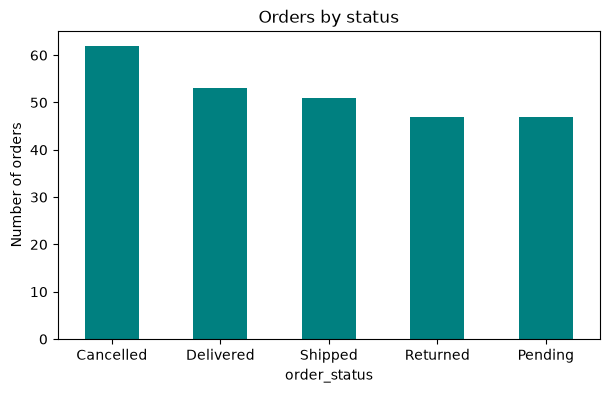

In [21]:
df["order_status"].value_counts().plot(kind="bar", figsize=(7, 4), title="Orders by status", color="teal")
plt.ylabel("Number of orders")
plt.xticks(rotation=0)
plt.show()

#ORDERS BY DAYS OF WEEK

In [23]:
#2
print(df["order_date"].dtype)   # you will probably see str or object

converted = pd.to_datetime(df["order_date"], format="mixed", errors="coerce")
print(df.loc[converted.isnull() & df["order_date"].notnull(), "order_date"].unique())

str
<ArrowStringArray>
['Unknown']
Length: 1, dtype: str


In [25]:
df["order_date"] = pd.to_datetime(df["order_date"], format="mixed", errors="coerce")
print(df["order_date"].dtype) 

datetime64[us]


In [26]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = df["order_date"].dt.day_name().value_counts().reindex(days) 

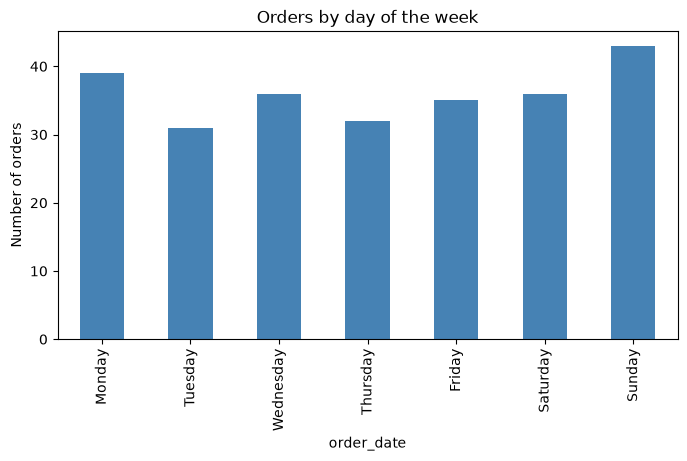

In [83]:
#which day of the week oders are mostly sold
by_day.plot(kind="bar", figsize=(8, 4), title="Orders by day of the week", color="steelblue")
plt.ylabel("Number of orders")
plt.show()

#3MONTHLY REVENUE

In [31]:
df["delivery_date"] = pd.to_datetime(df["delivery_date"], format="mixed", errors="coerce")
print(df["delivery_date"].dtype) 

datetime64[us]


In [32]:
sales = df[~df["order_status"].isin(["Cancelled", "Returned"])]
 
delivery_days = (df["delivery_date"] - df["order_date"]).dt.days   # days between order and delivery
 
gross = df["total_amount"].sum()                                    # value of ALL orders placed
lost  = df[df["order_status"].isin(["Cancelled", "Returned"])]["total_amount"].sum()

In [33]:
print("Total orders           :", len(df))
print("Value of all orders    :", round(gross))
print("Value lost (cancel/return) :", round(lost), "=", round(lost / gross * 100, 1), "% of all order value")
print("Orders counted as sales:", len(sales))
print("Total revenue (Rs.)    :", round(sales["total_amount"].sum()))
print("Average order value    :", round(sales["total_amount"].mean()))
print("Median order value     :", round(sales["total_amount"].median()))
print("Cancelled orders (%)   :", round((df["order_status"] == "Cancelled").mean() * 100, 1))
print("Returned orders (%)    :", round((df["order_status"] == "Returned").mean() * 100, 1))

Total orders           : 260
Value of all orders    : 3450369
Value lost (cancel/return) : 1532573 = 44.4 % of all order value
Orders counted as sales: 151
Total revenue (Rs.)    : 1917797
Average order value    : 12701
Median order value     : 2499
Cancelled orders (%)   : 23.8
Returned orders (%)    : 18.1


In [34]:
print("Average delivery days  :", round(delivery_days.mean(), 1))

Average delivery days  : 5.5


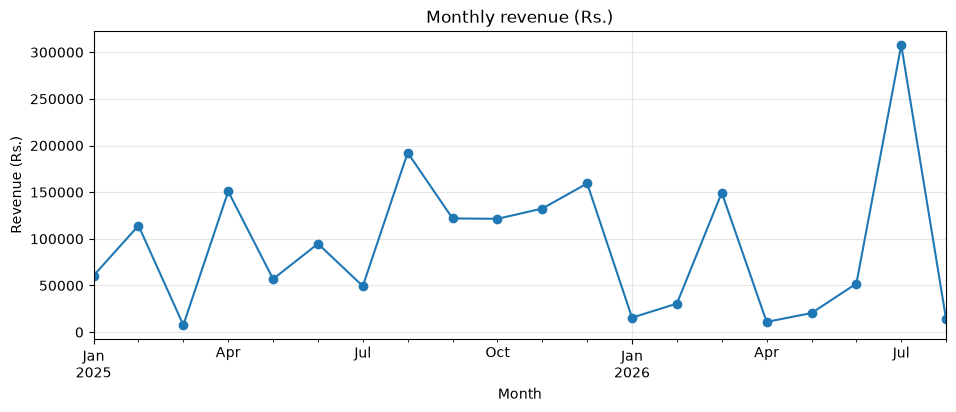

In [35]:
sales = sales.copy()
sales["month"] = sales["order_date"].dt.to_period("M")          # 2025-03-14 -> 2025-03
monthly = sales.groupby("month")["total_amount"].sum()
 
monthly.plot(kind="line", marker="o", figsize=(11, 4), title="Monthly revenue (Rs.)")
plt.ylabel("Revenue (Rs.)")
plt.xlabel("Month")
plt.grid(alpha=0.3)
plt.show()

#4 REVENUE BY CATEGORY

In [39]:
by_category = sales.groupby("category")["total_amount"].sum().sort_values()

In [40]:
by_category

category
Beauty               7183.65
Books               29581.50
Sports              61663.55
Clothing           122450.15
Home & Kitchen     268582.15
Electronics       1428335.80
Name: total_amount, dtype: float64

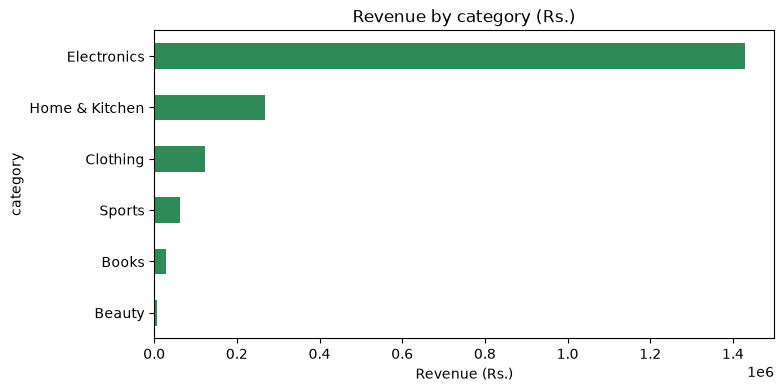

In [41]:
by_category.plot(kind="barh", figsize=(8, 4), title="Revenue by category (Rs.)", color="seagreen")
plt.xlabel("Revenue (Rs.)")
plt.show()

#MOST SOLD PRODUCTS

Text(0, 0.5, 'Product')

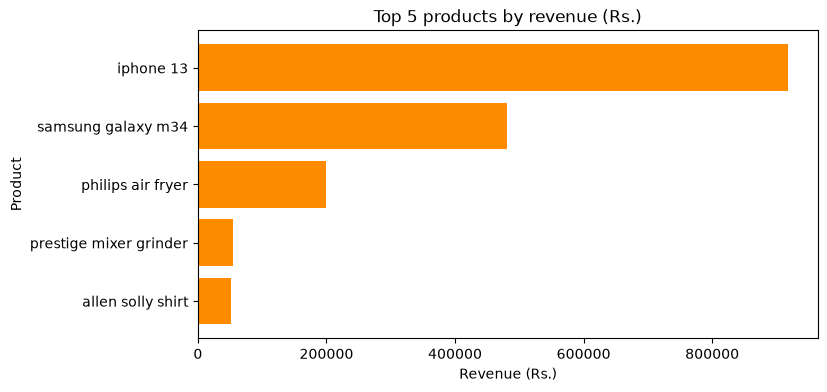

In [49]:
#4
top_products = sales.groupby("product_name")["total_amount"].sum().sort_values().tail(5)

plt.figure(figsize=(8, 4))
plt.barh(top_products.index, top_products.values, color="darkorange")
plt.title("Top 5 products by revenue (Rs.)")
plt.xlabel("Revenue (Rs.)")
plt.ylabel("Product")

#REVENUE BY CITY

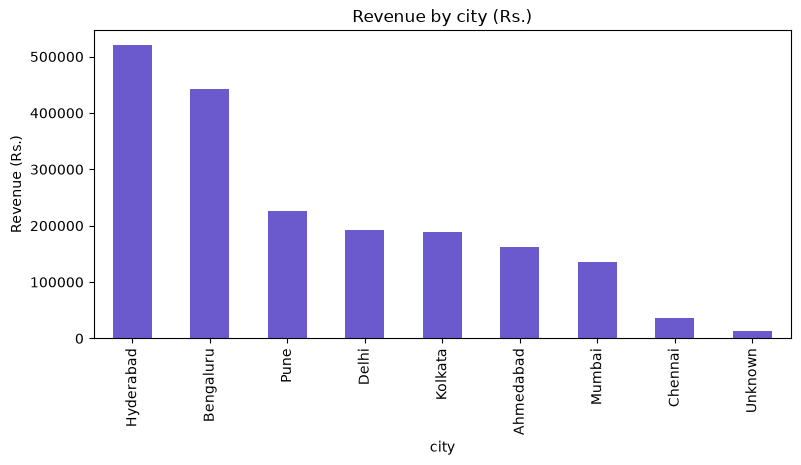

In [52]:
#5
by_city = sales.groupby("city")["total_amount"].sum().sort_values(ascending=False)
 
by_city.plot(kind="bar", figsize=(9, 4), title="Revenue by city (Rs.)", color="slateblue")
plt.ylabel("Revenue (Rs.)")
plt.show()

#CANCELLATION BY PAYMENT METHOD

In [61]:
#6.
cancel_rate = (df["order_status"] == "Cancelled").groupby(df["payment_method"]).sum()

In [62]:
cancel_rate

payment_method
Cash on Delivery    12
Credit Card         16
Debit Card          10
Net Banking          7
UPI                 14
Unknown              3
Name: order_status, dtype: int64

In [64]:
 df["payment_method"].value_counts()

payment_method
UPI                 58
Credit Card         54
Cash on Delivery    53
Debit Card          45
Net Banking         42
Unknown              8
Name: count, dtype: int64

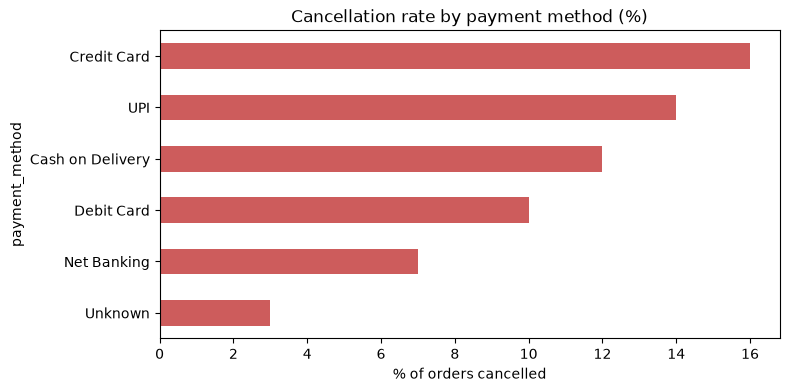

In [68]:
cancel_rate.sort_values().plot(kind="barh", figsize=(8, 4), title="Cancellation rate by payment method (%)", color="indianred")
plt.xlabel("% of orders cancelled")
plt.show()

#CORRELATION

              quantity  unit_price  discount_pct  total_amount
quantity          1.00       -0.02         -0.04          0.18
unit_price       -0.02        1.00         -0.03          0.90
discount_pct     -0.04       -0.03          1.00         -0.10
total_amount      0.18        0.90         -0.10          1.00


<Axes: >

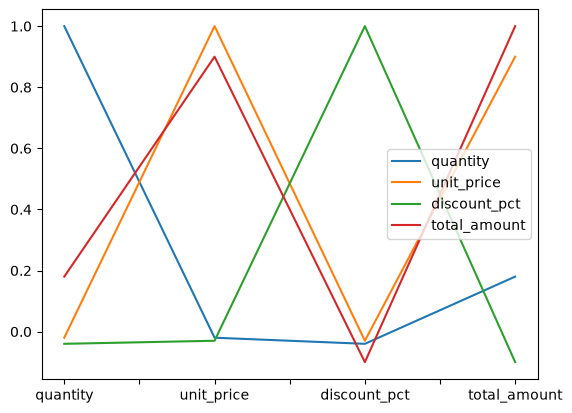

In [72]:
#7
corr = df[["quantity", "unit_price", "discount_pct", "total_amount"]].corr().round(2)
print(corr)
corr.plot()

#OUTLIERS PLOT

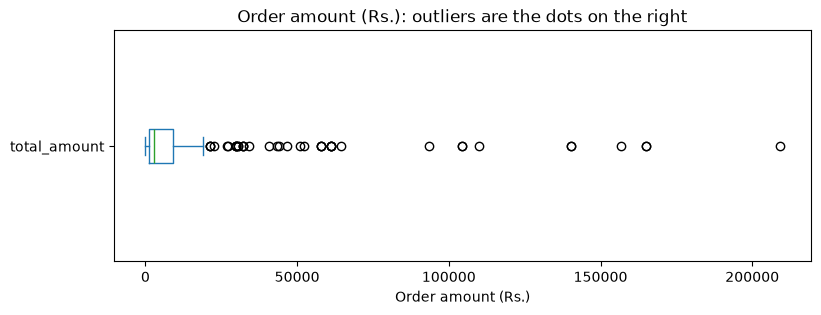

In [73]:
#8
df["total_amount"].plot(kind="box", vert=False, figsize=(9, 3), title="Order amount (Rs.): outliers are the dots on the right")
plt.xlabel("Order amount (Rs.)")
plt.show()

#OUTLIERS

In [74]:
q1 = df["total_amount"].quantile(0.25)
q3 = df["total_amount"].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
 
outliers = df[df["total_amount"] > upper_limit]
print("Upper limit (Rs.):", round(upper_limit))
print("Number of outlier orders:", len(outliers))
print("Outliers are", round(len(outliers) / len(df) * 100, 1), "% of orders but",
      round(outliers["total_amount"].sum() / df["total_amount"].sum() * 100, 1), "% of order value")
print(outliers["product_name"].value_counts())

Upper limit (Rs.): 21061
Number of outlier orders: 40
Outliers are 15.4 % of orders but 75.4 % of order value
product_name
samsung galaxy m34    18
iphone 13             13
philips air fryer      9
Name: count, dtype: int64


#INSIGHTS

1.Revenue depends on a few expensive products.** Electronics is 73.8% of revenue (₹13.8 lakh of ₹18.8 lakh) but only 22% of orders.
The iPhone 13 alone brings 48.9% of revenue, and the top 3 products (iPhone 13, Samsung Galaxy M34, Philips Air Fryer) bring 83.6%.
An average Electronics order is ₹46,166, against ₹513 for Beauty. *Action: protect stock and pricing of these 3 products; 
lower-priced categories need volume to matter

2. Almost half of the order value never becomes revenue.** 23.0% of orders are cancelled and 18.7% are returned, so only 21% are delivered. The cancelled and returned orders are worth ₹15.3 lakh, which is 44.9% of all order value (₹34.1 lakh). *Action: find out why orders are cancelled and returned, because this is the biggest leak in the data.*

3. Cancellations differ by payment method.** Credit Card orders are cancelled most (31.4%) and Net Banking least (14.6%); UPI (22.8%) and Cash on Delivery (22.6%) are in between. Each method has only 41 to 57 orders, so this is a lead to investigate, not a proven cause.

4.Revenue is lumpy and has anomalies.** The average order is ₹12,768 but the median is only ₹2,499, because a few big orders pull the average up. 35 outlier orders (13.9% of orders) make up 72.5% of order value, and all of them are iPhone, Samsung or Air Fryer orders. July 2026 is an anomalous month: ₹3.08 lakh, about 3.3 times the monthly average of ₹93,844, and 53.6% of it comes from one iPhone order of ₹1,64,997. The largest order in the whole file (₹2.09 lakh, an iPhone) was cancelled. Big orders are cancelled or returned about as often as normal ones (42.9% vs 41.5%).

5.Two cities generate half of the revenue.** Hyderabad (25.3%) and Bengaluru (23.6%) together make 48.9%. Chennai is the weakest at 1.9%, which is worth checking: is it a small market or a delivery or marketing gap?

6. Order value is driven by price, not by quantity or discounts.** Order amount has a strong relationship with unit price (correlation 0.90) and a weak one with quantity (0.18). Discount has almost no relationship with quantity (-0.05), so discounts of 0 to 20% do not lead customers to buy more items.